In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/Users/hongmo/Desktop/Gradient Boosting"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_and_split_data
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Load final trained pipeline
model_path = PROJECT_ROOT / "outputs" / "xgboost_refitted.joblib"

final_pipeline = joblib.load(model_path)

print("Final model loaded successfully!")

Final model loaded successfully!


In [2]:
data_path = PROJECT_ROOT / "data" / "application_train.csv"

X_train, X_val, X_test, y_train, y_val, y_test = (
    load_and_split_data(data_path)
)

print("Test set shape:", X_test.shape)
print("Test target distribution:")
print(y_test.value_counts(normalize=True))

Test set shape: (61503, 120)
Test target distribution:
TARGET
0    0.91963
1    0.08037
Name: proportion, dtype: float64


In [3]:
# Predict probability of TARGET = 1
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]

print("First 10 predicted probabilities:")
print(y_test_prob[:10])

First 10 predicted probabilities:
[0.13479093 0.24070522 0.09564497 0.02588196 0.05031299 0.11123633
 0.07611351 0.02384185 0.10387761 0.09342308]


In [4]:
# Calculate threshold-independent metrics
test_auc = roc_auc_score(y_test, y_test_prob)
test_ap = average_precision_score(y_test, y_test_prob)

# Compare with validation performance
validation_auc = 0.7605

print("Final Out-of-Sample Evaluation")
print("-" * 35)

print(f"Test ROC-AUC:       {test_auc:.4f}")
print(f"Test AP:            {test_ap:.4f}")
print(f"Validation ROC-AUC: {validation_auc:.4f}")
print(f"Test - Val AUC:     {test_auc - validation_auc:+.4f}")

Final Out-of-Sample Evaluation
-----------------------------------
Test ROC-AUC:       0.7602
Test AP:            0.2414
Validation ROC-AUC: 0.7605
Test - Val AUC:     -0.0003


In [5]:
# Pre-selected classification threshold
threshold = 0.2

# Convert probabilities into binary predictions
y_test_pred = (y_test_prob >= threshold).astype(int)

# Calculate metrics
precision = precision_score(
    y_test, y_test_pred, zero_division=0
)

recall = recall_score(
    y_test, y_test_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_test_pred, zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred
).ravel()

print(f"Threshold: {threshold}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nConfusion Matrix Counts:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

Threshold: 0.2
Precision: 0.2834
Recall:    0.2925
F1-Score:  0.2879

Confusion Matrix Counts:
TN: 52904
FP: 3656
FN: 3497
TP: 1446


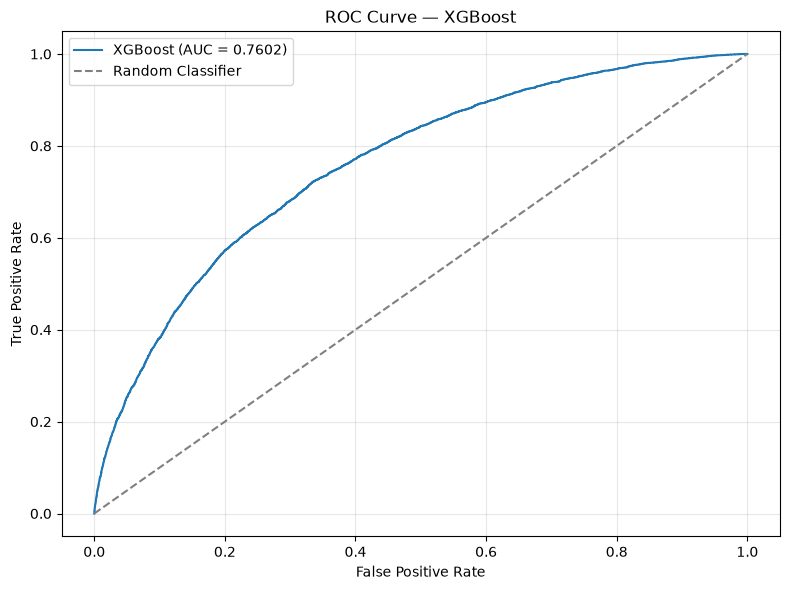

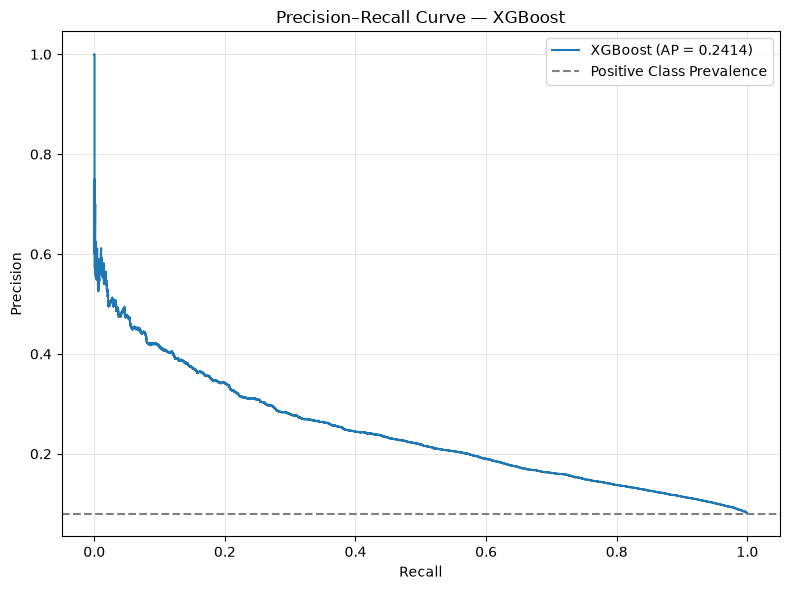

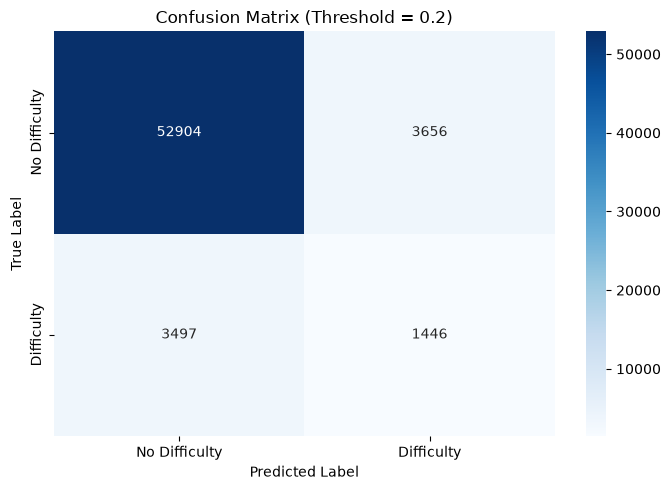

              precision    recall  f1-score   support

           0       0.94      0.94      0.94     56560
           1       0.28      0.29      0.29      4943

    accuracy                           0.88     61503
   macro avg       0.61      0.61      0.61     61503
weighted avg       0.89      0.88      0.88     61503



In [6]:
from src.evaluation import (
    plot_roc_curve,
    plot_precision_recall_curve,
    plot_confusion_matrix
)

# ROC Curve
plot_roc_curve(y_test, y_test_prob)

# Precision–Recall Curve
plot_precision_recall_curve(y_test, y_test_prob)

# Confusion Matrix
plot_confusion_matrix(
    y_test,
    y_test_prob,
    threshold=0.2
)

In [7]:
results = pd.DataFrame([{
    "Model": "XGBoost (Regularized + Refitted)",
    "Boosting Rounds": 685,
    "Validation ROC-AUC": 0.7605,
    "Test ROC-AUC": test_auc,
    "Test Average Precision": test_ap,
    "Threshold": threshold,
    "Test Precision": precision,
    "Test Recall": recall,
    "Test F1": f1
}])

output_path = PROJECT_ROOT / "outputs" / "final_test_results.csv"

results.to_csv(output_path, index=False)

display(results.round(4))

,Model,Boosting Rounds,Validation ROC-AUC,Test ROC-AUC,Test Average Precision,Threshold,Test Precision,Test Recall,Test F1
0,XGBoost (Regularized + Refitted),685,0.7605,0.7602,0.2414,0.2,0.2834,0.2925,0.2879
